In [6]:
from importlib import reload

from func_strain import import_raw_strain_measurements, correct_temp, correct_angle, strain_to_NM
import func_strain

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml

In [7]:
reload(func_strain)

<module 'func_strain' from 'c:\\Users\\max\\OneDrive - Delft University of Technology\\1. Master Thesis\\Thesis_Max_Blankwater\\Measurement_interpretation\\strain\\func_strain.py'>

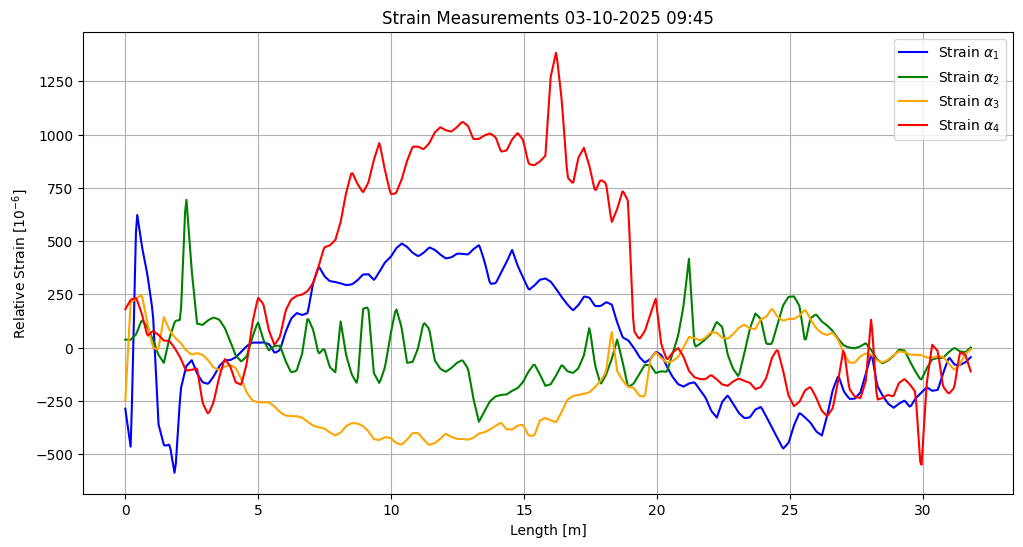

$\alpha_1$ max: 622.8707392192981, $\alpha_1$ min: -586.9310850103229
$\alpha_2$ max: 693.6083809523781, $\alpha_2$ min: -347.6141818181654
$\alpha_3$ max: 246.92364980880996, $\alpha_3$ min: -456.08301677220896
$\alpha_4$ max: 1383.9245252525889, $\alpha_4$ min: -550.0596729197007


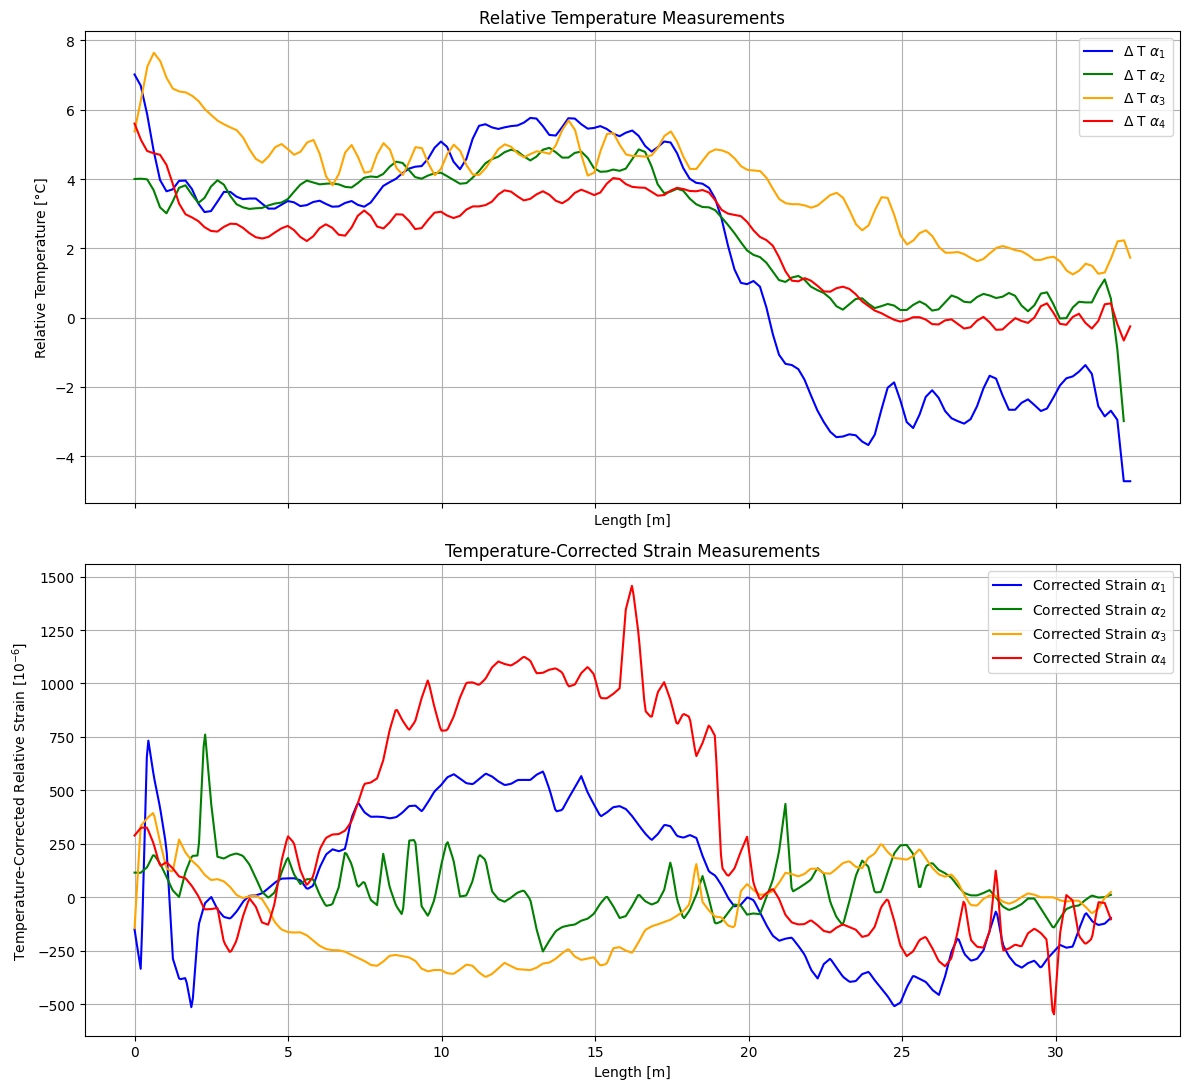

alpha_1 max: 732.4845574011042, alpha_1 min: -514.819812283048
alpha_2 max: 760.9523809523795, alpha_2 min: -253.99999999997087
alpha_3 max: 393.5549225360761, alpha_3 min: -372.4048349540349
alpha_4 max: 1456.8888888889387, alpha_4 min: -548.0105820106176


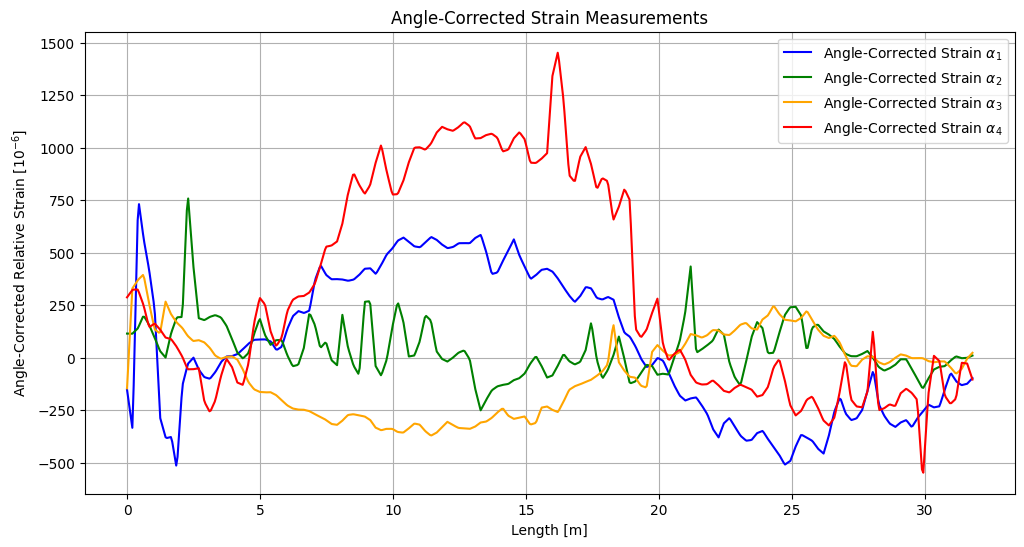

alpha_1 max: 731.2867007930597, alpha_1 min: -512.5140488841693
alpha_2 max: 758.2138799848395, alpha_2 min: -249.63520193974898
alpha_3 max: 394.2178454257466, alpha_3 min: -369.22462480768746
alpha_4 max: 1451.8685635321563, alpha_4 min: -546.6498678686895
R_o: 710.00 mm, R_i: 690.00 mm, E: 210.00 GPa
I: 2.16e+10 mm^4, A: 8.80e+04 mm^2, W: 3.04e+07 mm^3
Max M: 3487.18 kNm, Min M: -1809.46 kNm, Max N: 7252.26 kN, Min N: -4363.74 kN


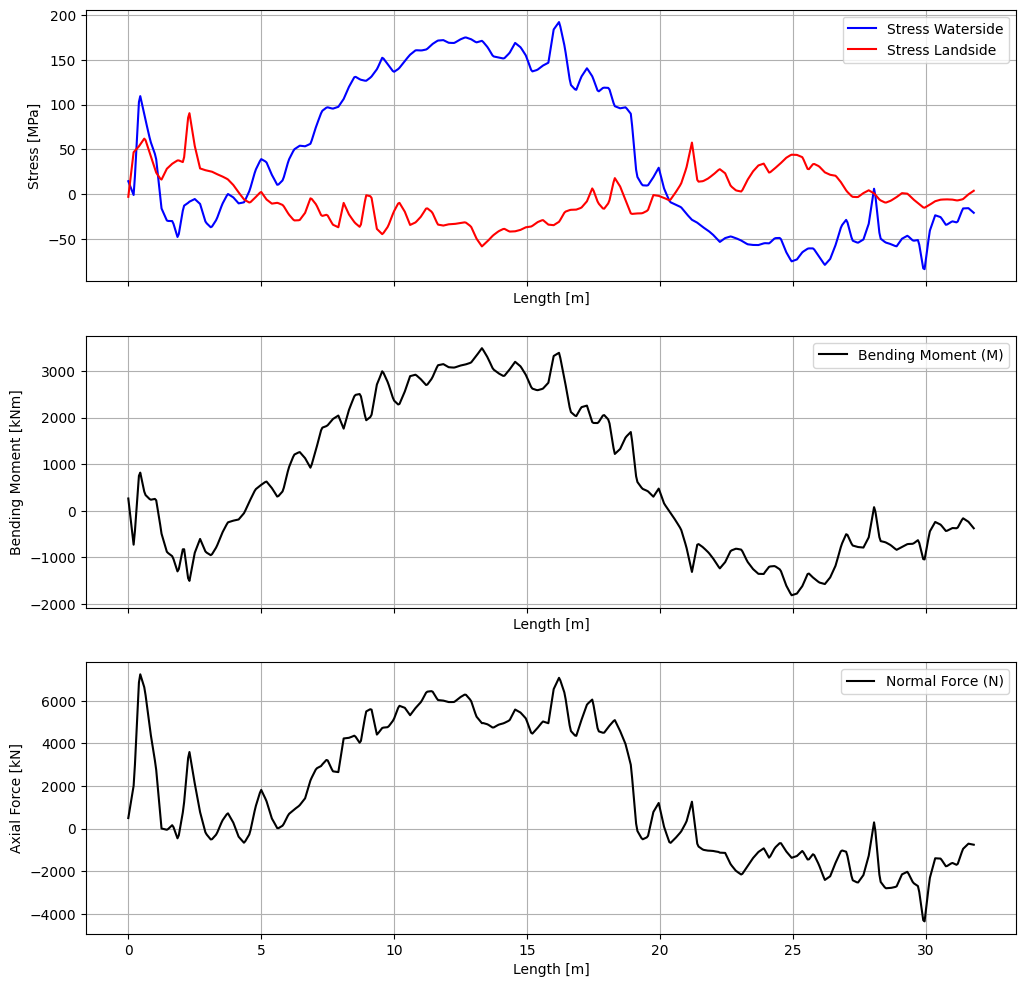

,Length,Strain_a1,Strain_a2,Strain_a3,Strain_a4,N,M,U
0,0.00,-151.314122,115.469821,-145.026135,287.863513,494.109133,264.757404,-68.407216
1,0.05,-196.710408,115.333111,-26.255412,296.616625,872.754406,17.259675,-68.407216
2,0.10,-242.106693,115.196401,92.515310,305.369737,1251.399679,-230.238054,-67.951013
3,0.15,-287.502978,115.059691,211.286033,314.122848,1630.044952,-477.735783,-67.494829
4,0.20,-332.899264,114.922982,330.056755,322.875960,2008.690225,-725.233511,-67.038390
...,...,...,...,...,...,...,...,...
632,31.60,-123.236703,0.129987,-3.568441,-27.241098,-710.806997,-234.367362,0.005421
633,31.65,-116.510227,2.834684,3.308165,-46.223573,-723.159122,-269.174037,0.003742
634,31.70,-109.783752,5.539380,10.184771,-65.206047,-735.511248,-303.980711,0.002322
635,31.75,-103.057277,8.244076,17.061377,-84.188521,-747.863373,-338.787386,0.001200


In [8]:
# Import and correct strain measurements
section = '84'
date = '03-10-2025 09:45'
date_ref = '25-04-2023 09:02'
plot = True
outpath = "..\\..\\Data\\Measurements\\Strains"

    

df = import_raw_strain_measurements(f'strainmeasurements\\BP_strain_mt{section}_031020250945.xlsx', plot=plot, type='BP',
                                      savepath='calculations', date=date, date_ref=date_ref, section=section)
df = correct_temp(df, f'temperaturemeasurements\\BP_TC_mt{section}_031020250945.xlsx', plot=plot,
                  type='BP', savepath='calculations', date=date, date_ref=date_ref, section=section)
# define geometric parameters for the beam cross-section
R = 1420 / 2
r = R + (0.5 * 60)
R_i = R - (20)
df = correct_angle(df, R=R, r=r, plot=plot,
                   savepath='calculations', date=date, date_ref=date_ref, section=section
                  )
df = strain_to_NM(df, R_o=R, R_i=R_i, plot=plot, 
                  savepath=outpath, date=date, date_ref=date_ref, section=section, simplified=False
                  )
display(df)

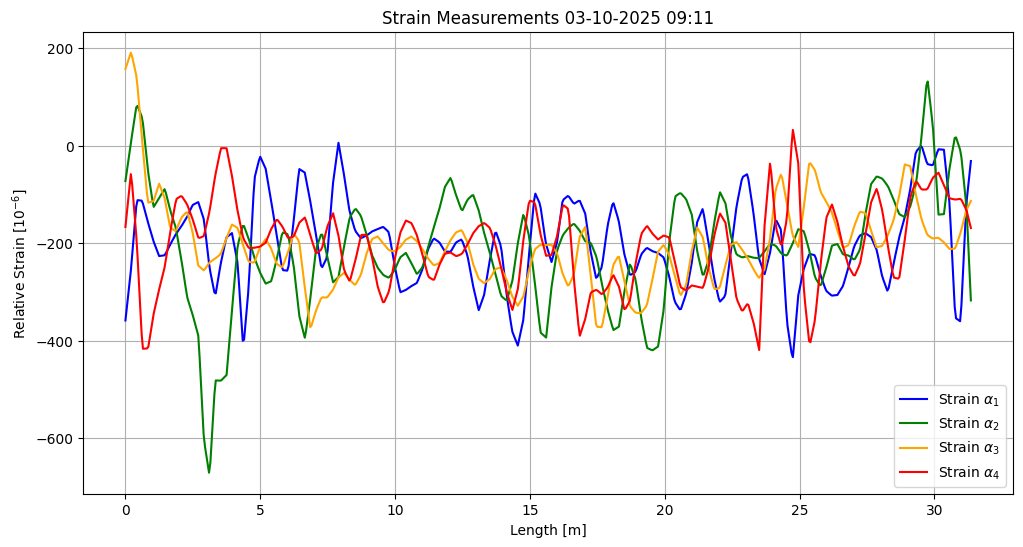

$\alpha_1$ max: 5.885414141402073, $\alpha_1$ min: -434.13187686388693
$\alpha_2$ max: 131.73387974986187, $\alpha_2$ min: -671.4178797498912
$\alpha_3$ max: 190.81543049537558, $\alpha_3$ min: -372.7066531985872
$\alpha_4$ max: 32.36288985089734, $\alpha_4$ min: -419.4606868686968


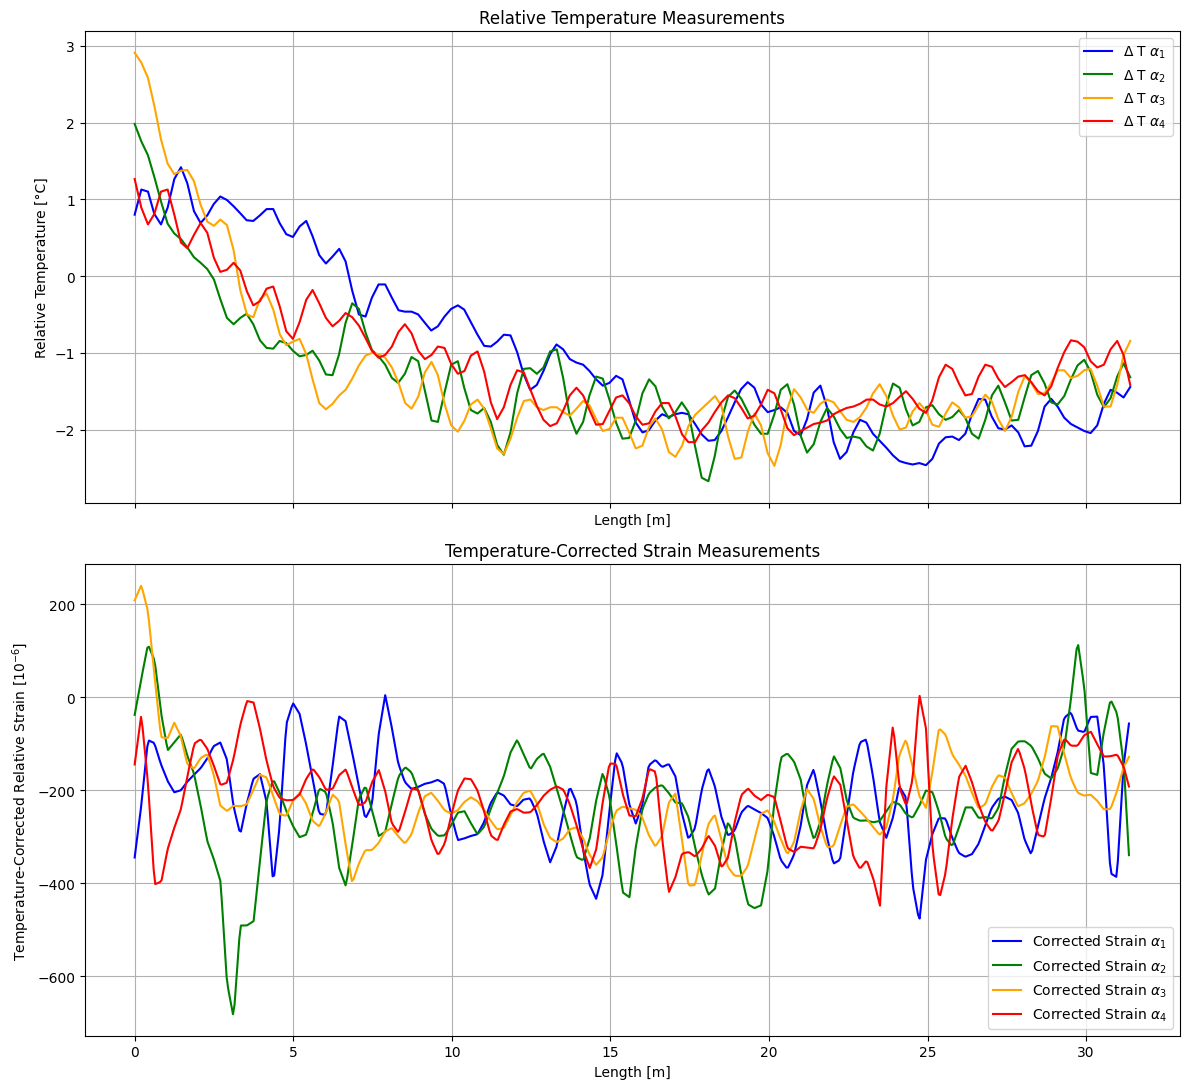

alpha_1 max: 3.9959595959351493, alpha_1 min: -476.35218855219586
alpha_2 max: 111.69966329962872, alpha_2 min: -682.1472823473018
alpha_3 max: 239.10149110145684, alpha_3 min: -405.18335738335384
alpha_4 max: 2.401539201559526, alpha_4 min: -448.4548167388212


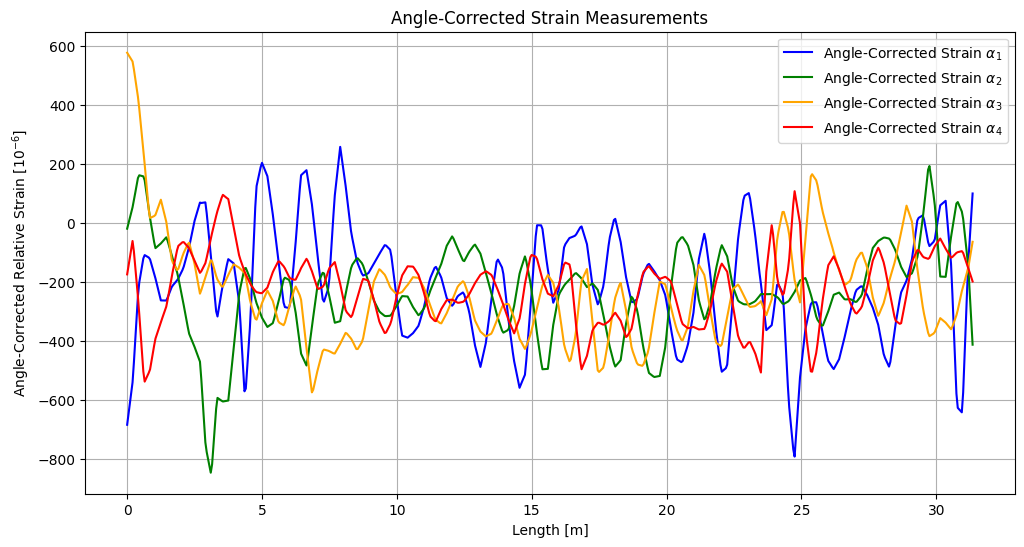

alpha_1 max: 257.29470681978813, alpha_1 min: -790.8475879429462
alpha_2 max: 192.39821607189106, alpha_2 min: -845.4993775024835
alpha_3 max: 575.8633652675378, alpha_3 min: -573.5396033751069
alpha_4 max: 107.24233369602395, alpha_4 min: -537.1552018112993
R: 300.00 mm, E: 30.00 GPa
I: 6.36e+09 mm^4, A: 2.83e+05 mm^2, W: 2.12e+07 mm^3
Max M: 153.10 kNm, Min M: -224.84 kNm, Max N: 170.57 kN, Min N: -3067.18 kN


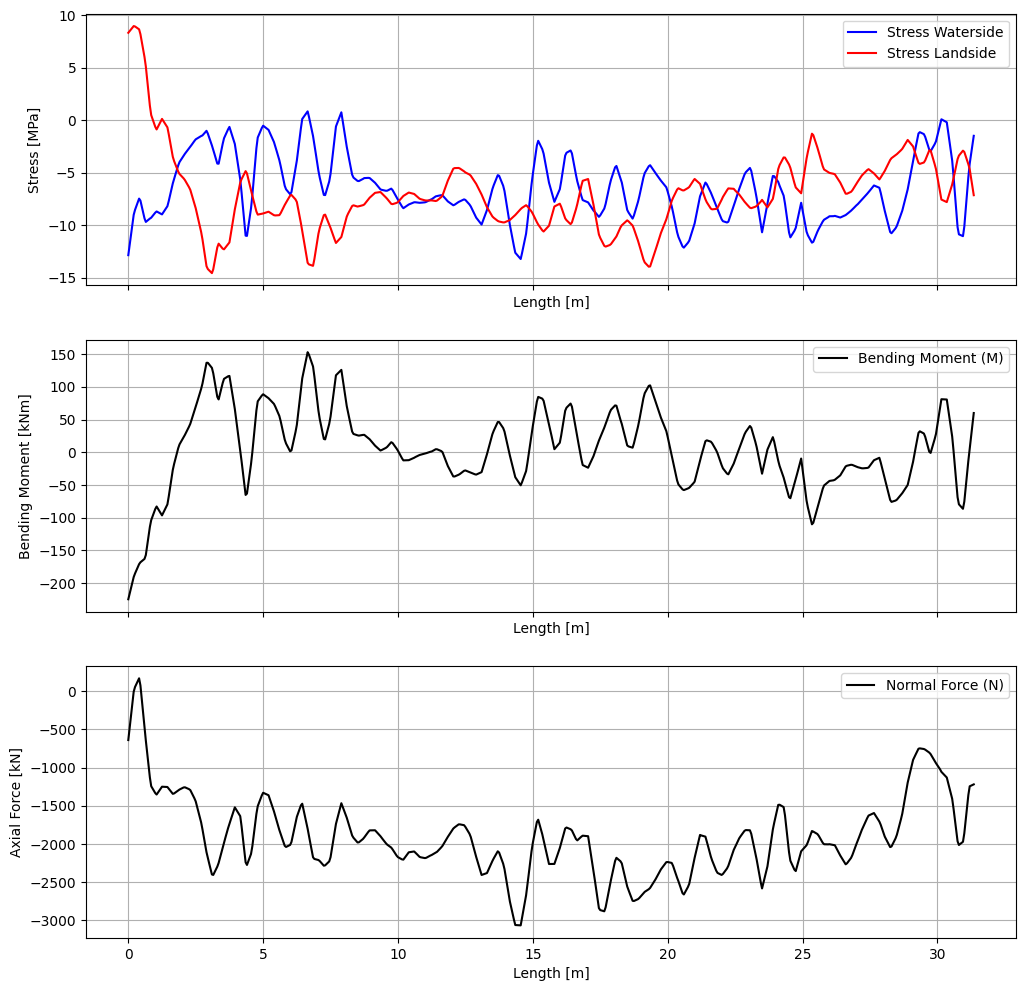

In [9]:
date = '03-10-2025 09:11'
date_ref = '18-04-2023 09:02'

df = import_raw_strain_measurements('strainmeasurements\\VIB_LZ_Strain_mt76_031020250911.xlsx', plot=plot, type='VP', date=date)
df = correct_temp(df, 'temperaturemeasurements\\VIB_L_TC_mt76_031020250911.xlsx', type='VP', plot=plot, date=date)

R = 600 / 2
r = R - 50
# alpha = [51.5, 141.9, 231.5, 321.9] # alpha on land
alpha = [58.2, 145.8, 238.2, 325.8] # alpha on water
df = correct_angle(df, R=R, r=r, plot=plot, type='VP', alpha=alpha,
                   savepath='calculations', date=date, date_ref=date_ref, side='LZ')
df = strain_to_NM(df, R_o=R, plot=plot, type='VP', E = 30,
                  savepath=outpath, date=date, date_ref=date_ref, side='LZ')

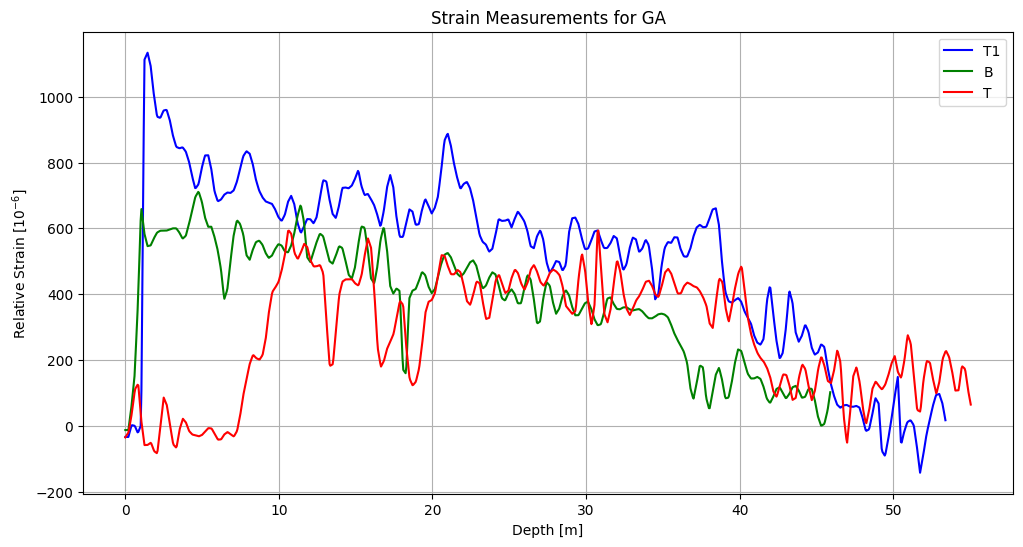

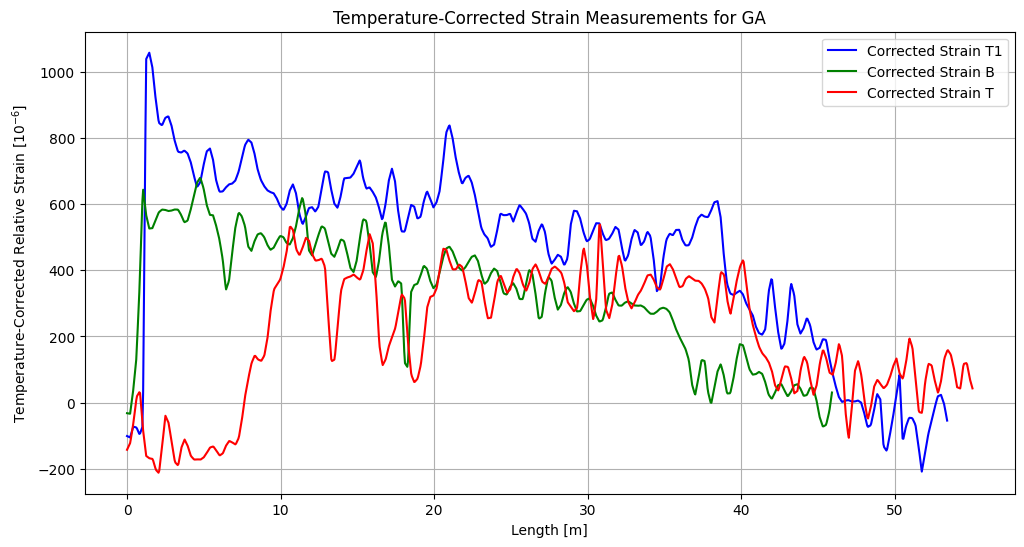

KeyError: 'Strain_a1'

In [10]:
date = '13-04-2023 13:51'
date_ref = '03-04-2023 11:11'
plot=True

df = import_raw_strain_measurements('strainmeasurements\\GA_strain_mt76_130420261351.xlsx', 
                                    plot=plot, type='GA')

df = correct_temp(df, 'temperaturemeasurements\\GA_TC_mt76_130420261351.xlsx', 
                  type='GA', plot=plot)

R_o = 600 / 2
R_i = R_o - 28

df = strain_to_NM(df, R_o=R_o, R_i=R_i, plot=plot, type='GA', E = 34, 
                  savepath=outpath, date=date, date_ref=date_ref, side='LZ')
display(df)


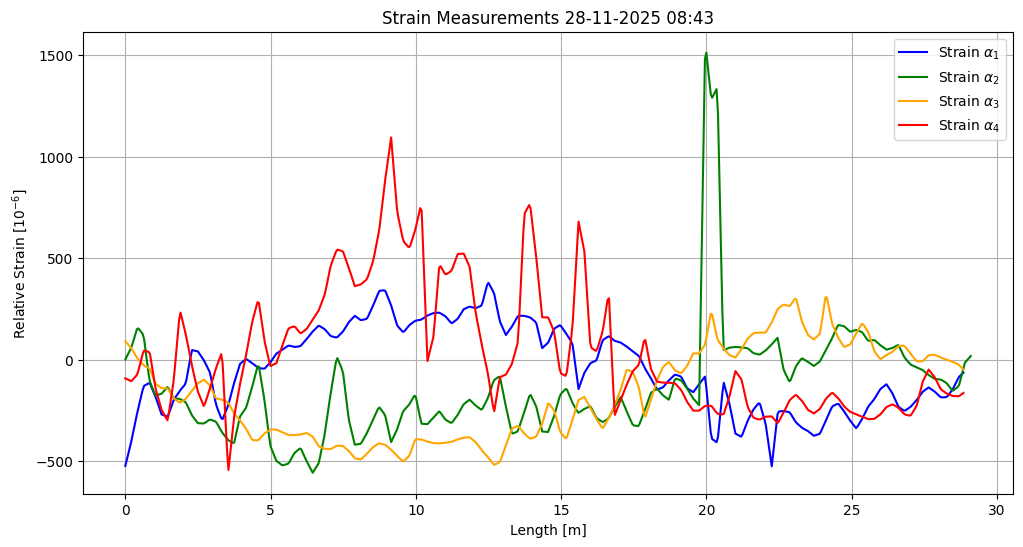

$\alpha_1$ max: 378.78268076265925, $\alpha_1$ min: -524.3333678625685
$\alpha_2$ max: 1511.8153342953483, $\alpha_2$ min: -556.0014949494856
$\alpha_3$ max: 308.79772072571814, $\alpha_3$ min: -516.8393002967152
$\alpha_4$ max: 1094.4735757576113, $\alpha_4$ min: -542.2929658490234


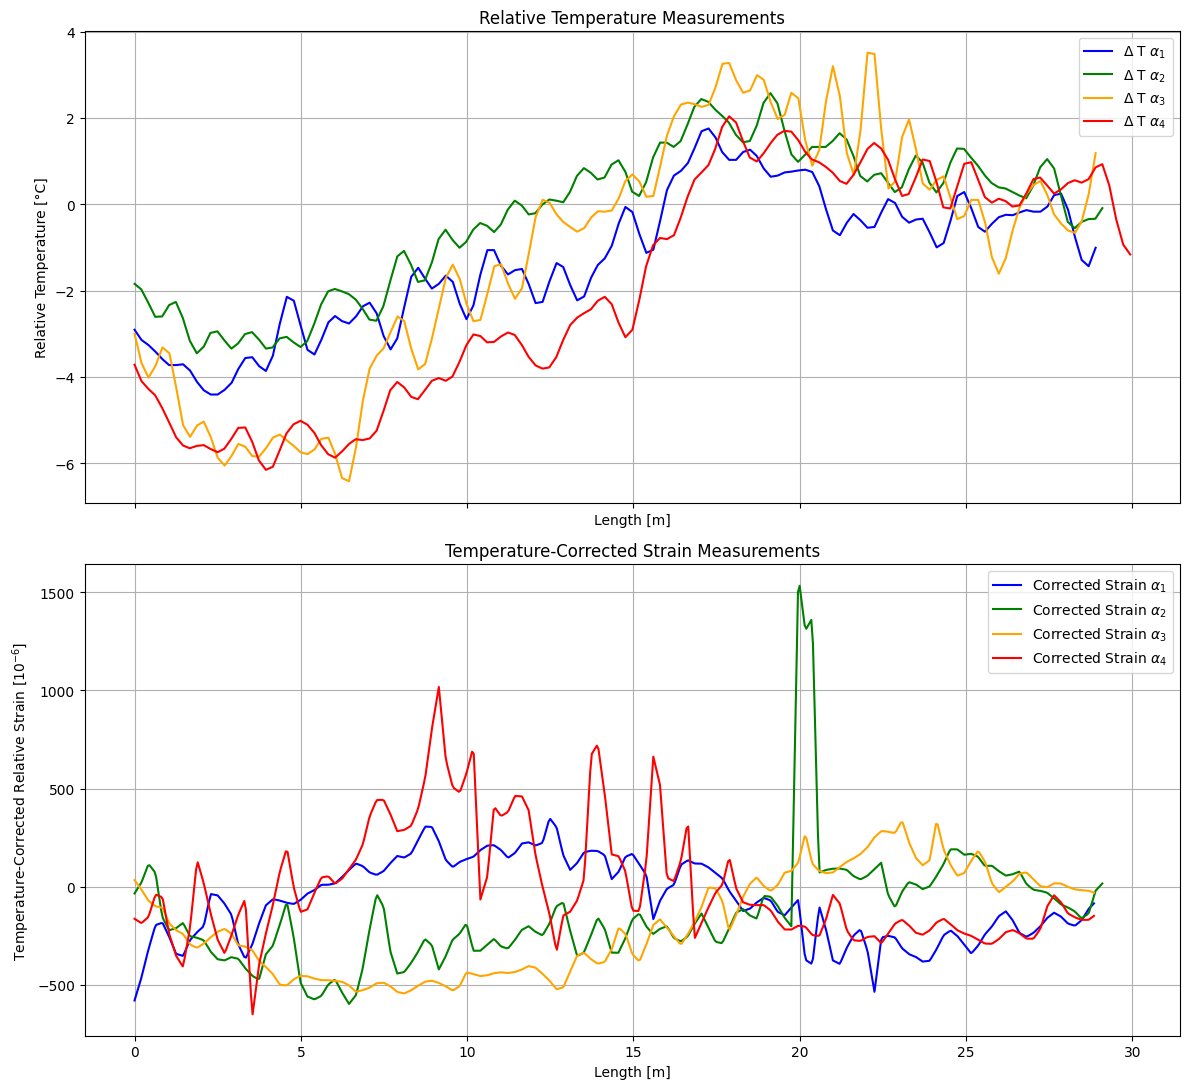

alpha_1 max: 345.1274080354083, alpha_1 min: -578.8328387735237
alpha_2 max: 1531.5066797498944, alpha_2 min: -596.3158949494906
alpha_3 max: 328.0486081672807, alpha_3 min: -542.6805143422476
alpha_4 max: 1016.6666666667151, alpha_4 min: -649.1413476672005


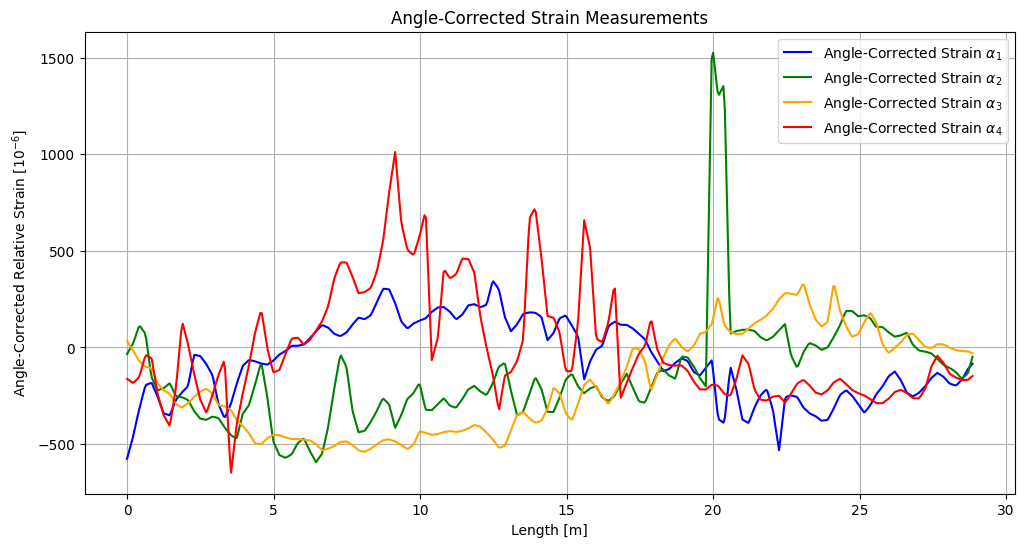

alpha_1 max: 342.3571356101108, alpha_1 min: -576.7821176275241
alpha_2 max: 1525.7138905040847, alpha_2 min: -594.0171447982452
alpha_3 max: 325.9281706374721, alpha_3 min: -540.3648567485496
alpha_4 max: 1011.855363911238, alpha_4 min: -648.4876323181946
R_o: 710.00 mm, R_i: 690.00 mm, E: 210.00 GPa
I: 2.16e+10 mm^4, A: 8.80e+04 mm^2, W: 3.04e+07 mm^3
Max M: 3417.05 kNm, Min M: -3397.82 kNm, Max N: 6279.44 kN, Min N: -7929.52 kN


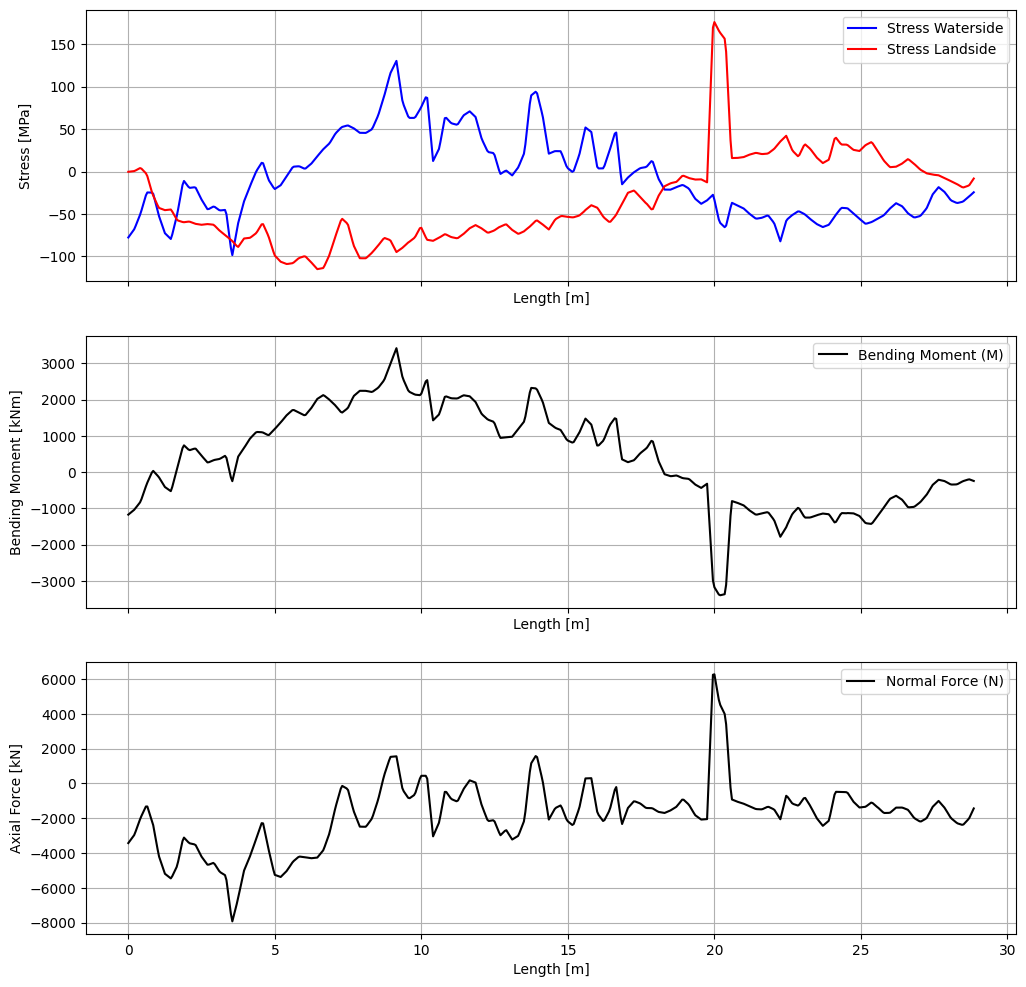

,Length,Strain_a1,Strain_a2,Strain_a3,Strain_a4,N,M,U
0,0.00,-576.782118,-34.432166,31.777172,-162.678946,-3427.196737,-1174.401941,3.950677
1,0.05,-548.748820,-21.007464,20.323405,-167.854362,-3312.533766,-1141.110046,3.950677
2,0.10,-520.715523,-7.607270,8.869638,-173.029861,-3197.984350,-1107.779220,4.216338
3,0.15,-492.682226,5.792925,-2.584130,-178.205360,-3083.434935,-1074.448395,4.483258
4,0.20,-464.648929,19.193119,-14.037897,-183.380859,-2968.885519,-1041.117569,4.751403
...,...,...,...,...,...,...,...,...
578,28.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
579,28.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN
580,29.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
581,29.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Import and correct strain measurements
section = '68'
date = '28-11-2025 08:43'
date_ref = '18-12-2022 12:37'
plot = True

    

df = import_raw_strain_measurements('strainmeasurements\\BP_strain_mt68_281120250843.xlsx', plot=plot, type='BP',
                                      savepath='calculations', date=date, date_ref=date_ref, section=section)
df = correct_temp(df, 'temperaturemeasurements\\BP_TC_mt68_281120250843.xlsx', plot=plot,
                  type='BP', savepath='calculations', date=date, date_ref=date_ref, section=section)
R = 1420 / 2
r = R + (0.5 * 60)
R_i = R - (20)
df = correct_angle(df, R=R, r=r, plot=plot,
                   savepath='calculations', date=date, date_ref=date_ref, section=section
                  )
df = strain_to_NM(df, R_o=R, R_i=R_i, plot=plot, 
                  savepath=outpath, date=date, date_ref=date_ref, section=section, simplified=False
                  )
display(df)